# Challenge – Classificação Linear: Renewable Energy Production Dataset (2010-2020)

**Integrantes do grupo:**

Vitor Nascimento RM: 571873

Nickollas Korner RM: 569655

João Pedro Ferrari RM: 573037

Lucca Bracco RM: 570175

Pierre Biason RM: 569718

Lucas Santana RM: 573197


**Dataset:** https://www.kaggle.com/datasets/itsrohithere/renewable-energy-production-dataset-2010-2020

**Ambiente:** Google Colab. Para executar, envie o arquivo `Renewable_Energy_Data.csv` para a
sessão do Colab (ícone de pasta, à esquerda → Upload) e rode todas as células.
Se o CSV não estiver na pasta, o código baixa o dataset direto do Kaggle via `kagglehub`.

In [1]:
import os
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.width', 140)
sns.set_theme(style='white')
SEED = 42  # semente fixa para os resultados serem reprodutíveis

## 01) Análise do dataset
### a) Carregar os dados em um DataFrame

In [2]:
ARQUIVO = 'Renewable_Energy_Data.csv'

if not os.path.exists(ARQUIVO):
    # Alternativa: baixa direto do Kaggle (dataset público)
    import kagglehub
    pasta = kagglehub.dataset_download('itsrohithere/renewable-energy-production-dataset-2010-2020')
    ARQUIVO = glob.glob(os.path.join(pasta, '**', '*.csv'), recursive=True)[0]

df = pd.read_csv(ARQUIVO)
print('Formato (linhas, colunas):', df.shape)
print(df.head())
print('\nValores ausentes no total:', df.isna().sum().sum())
print('\nDistribuição do target:')
print(df['Energy_Class'].value_counts())

100%|██████████| 46.5k/46.5k [00:00<00:00, 40.1MB/s]

Extracting files...
Formato (linhas, colunas): (1000, 11)
  Region Energy_Source  Temperature_C  Wind_Speed_m_s  Solar_Radiation_kWh_m2  Rainfall_mm  Season  Efficiency_Ratio  \
0  North         Hydro         13.821          14.362                   8.835        3.351  Winter           125.449   
1  North         Solar         36.973          19.110                   4.483       48.767  Winter            16.325   
2   East         Hydro         33.973           0.365                   5.104       40.849  Winter           155.637   
3  South         Solar         -2.965           3.916                   6.266       42.627  Spring           675.517   
4  North          Wind         -3.813           0.151                   9.264       46.898  Spring           626.048   

   Lagged_Production_MWh  Combined_Weather_Index Energy_Class  
0               1419.514                   1.565       Medium  
1               4769.330                   0.621          Low  
2               1005.078     

### b) Encoding do target (`Energy_Class`) para variável numérica

`Energy_Class` é **ordinal** (Low < Medium < High). Por isso usamos um mapeamento explícito
Low=0, Medium=1, High=2. O `LabelEncoder` ordenaria em ordem alfabética (High=0, Low=1,
Medium=2), o que quebraria a ordem natural e distorceria a correlação.

In [3]:
MAPA_CLASSES = {'Low': 0, 'Medium': 1, 'High': 2}
NOMES_CLASSES = ['Low', 'Medium', 'High']

df['Energy_Class_num'] = df['Energy_Class'].map(MAPA_CLASSES)
print(df[['Energy_Class', 'Energy_Class_num']].drop_duplicates()
      .sort_values('Energy_Class_num').to_string(index=False))

Energy_Class  Energy_Class_num
         Low                 0
      Medium                 1
        High                 2


### c) Matriz de correlação entre as features (incluindo `Energy_Class`)

As colunas categóricas nominais (`Region`, `Energy_Source`, `Season`) foram transformadas com
*one-hot encoding* para que **todas** as colunas da tabela entrem na matriz.

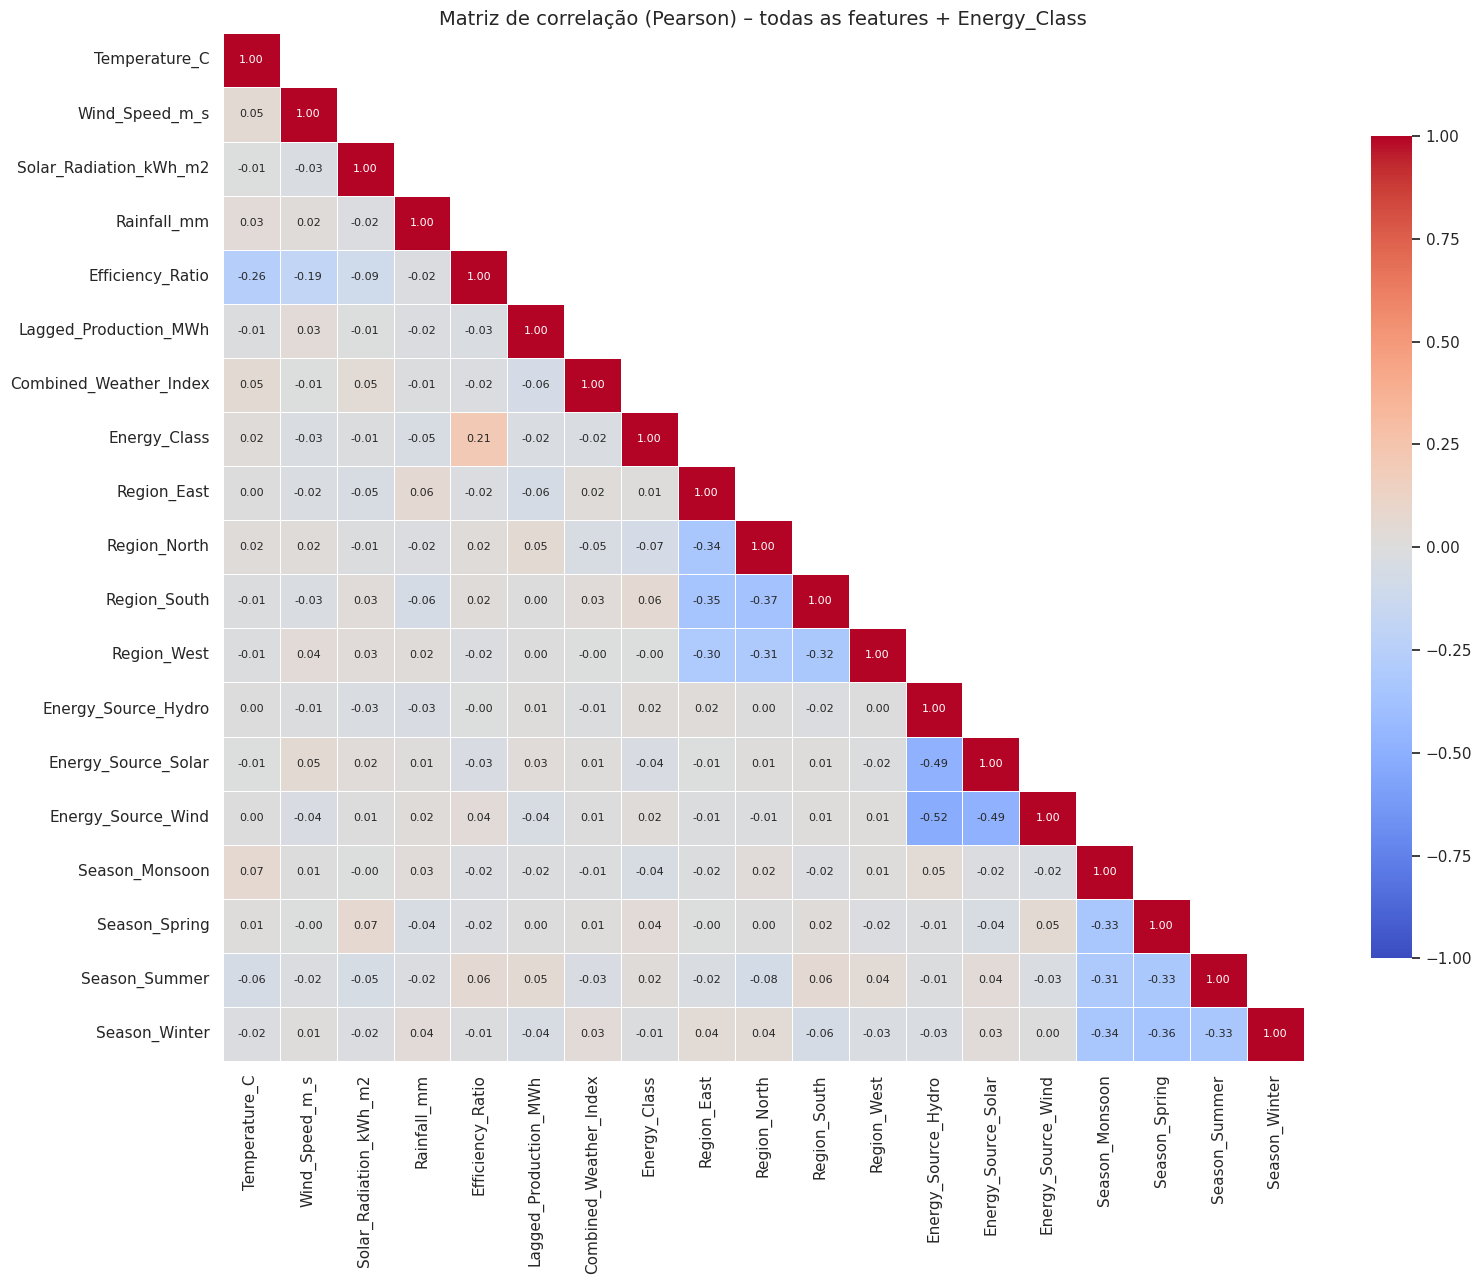

In [4]:
CATEGORICAS = ['Region', 'Energy_Source', 'Season']
df_corr = pd.get_dummies(df.drop(columns='Energy_Class'), columns=CATEGORICAS, dtype=int)
df_corr = df_corr.rename(columns={'Energy_Class_num': 'Energy_Class'})

corr = df_corr.corr(method='pearson')

plt.figure(figsize=(16, 13))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, annot_kws={'size': 8}, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlação (Pearson) – todas as features + Energy_Class', fontsize=14)
plt.tight_layout()
plt.show()

In [5]:
# Correlação de cada feature com o target: Pearson (linear) x Spearman (monotônica, robusta a outliers)
corr_target = pd.DataFrame({
    'Pearson': df_corr.corr(method='pearson')['Energy_Class'],
    'Spearman': df_corr.corr(method='spearman')['Energy_Class'],
}).drop('Energy_Class').sort_values('Spearman', key=abs, ascending=False)
print(corr_target)

                        Pearson  Spearman
Efficiency_Ratio          0.211     0.743
Region_North             -0.065    -0.066
Combined_Weather_Index   -0.025    -0.060
Region_South              0.056     0.057
Rainfall_mm              -0.046    -0.046
Season_Monsoon           -0.045    -0.045
Season_Spring             0.039     0.041
Energy_Source_Solar      -0.035    -0.036
Wind_Speed_m_s           -0.027    -0.024
Energy_Source_Hydro       0.019     0.023
Lagged_Production_MWh    -0.024    -0.023
Season_Summer             0.020     0.018
Region_East               0.012     0.016
Season_Winter            -0.014    -0.015
Energy_Source_Wind        0.016     0.013
Temperature_C             0.018     0.010
Region_West              -0.004    -0.008
Solar_Radiation_kWh_m2   -0.008    -0.006


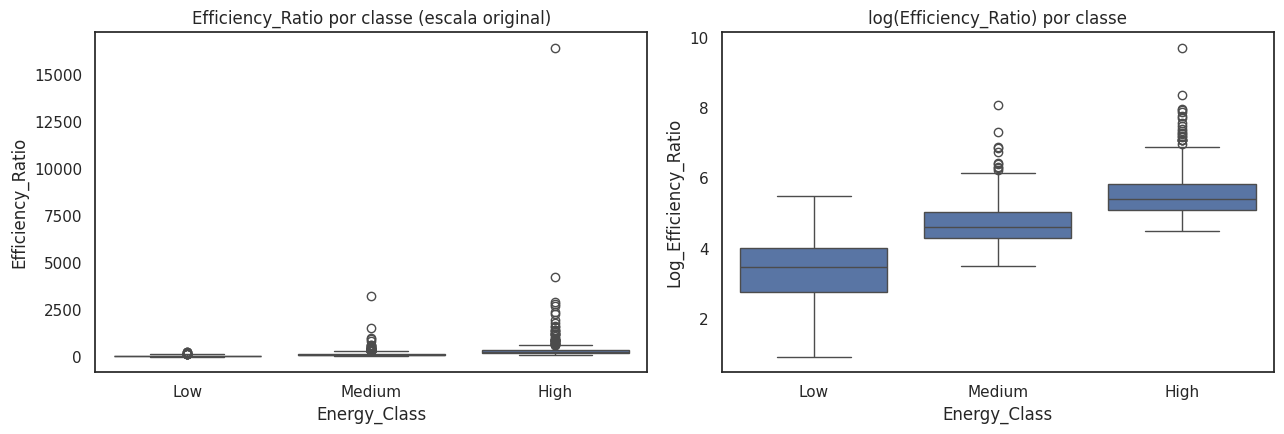

Correlação de Pearson de log(Efficiency_Ratio) com o target: 0.734

Correlação de log(Efficiency_Ratio) com as demais numéricas:
Temperature_C            -0.447
Wind_Speed_m_s           -0.272
Solar_Radiation_kWh_m2   -0.116
Rainfall_mm              -0.066
Lagged_Production_MWh    -0.032
Combined_Weather_Index   -0.058
Name: Log_Efficiency_Ratio, dtype: float64


In [6]:
# Efficiency_Ratio tem outliers extremos; em escala log, a relação com a classe fica nítida
df['Log_Efficiency_Ratio'] = np.log(df['Efficiency_Ratio'])

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x='Energy_Class', y='Efficiency_Ratio', order=NOMES_CLASSES, ax=eixos[0])
eixos[0].set_title('Efficiency_Ratio por classe (escala original)')
sns.boxplot(data=df, x='Energy_Class', y='Log_Efficiency_Ratio', order=NOMES_CLASSES, ax=eixos[1])
eixos[1].set_title('log(Efficiency_Ratio) por classe')
plt.tight_layout()
plt.show()

print('Correlação de Pearson de log(Efficiency_Ratio) com o target:',
      round(df['Log_Efficiency_Ratio'].corr(df['Energy_Class_num']), 3))
print('\nCorrelação de log(Efficiency_Ratio) com as demais numéricas:')
print(df[['Log_Efficiency_Ratio', 'Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2',
          'Rainfall_mm', 'Lagged_Production_MWh', 'Combined_Weather_Index']]
      .corr()['Log_Efficiency_Ratio'].drop('Log_Efficiency_Ratio').round(3))

### d) Com os resultados obtidos, é possível escolher algumas poucas features para a classificação ou é melhor utilizar todas? Justifique a sua escolha a partir da matriz de correlação.

**Resposta: é possível (e melhor) usar apenas algumas features.** Depois do one-hot, a tabela
tem 18 colunas, mas escolhemos só **7**. A matriz de correlação justifica essa escolha:

1. **`Efficiency_Ratio` é a única feature com relação relevante com `Energy_Class`.**
   O Pearson dá só **0,21**, mas o Spearman chega a **0,74**. A diferença vem dos outliers
   extremos (máximo acima de 16.000 com mediana perto de 140), que achatam a correlação linear.
   Em escala log, a relação vira linear (Pearson de log(Efficiency_Ratio) com o target ≈ 0,73).
   **É a feature principal e entra obrigatoriamente.**
2. **As 11 colunas categóricas (região, fonte de energia e estação) têm correlação praticamente
   nula com o target** (|r| < 0,07) e também quase nula com `Efficiency_Ratio`. Elas não trazem
   informação útil, só aumentam a dimensão do problema e o risco de ruído, então foram
   **descartadas**.
3. **As 6 variáveis numéricas climáticas/de produção também têm correlação quase nula com o
   target, mas `log(Efficiency_Ratio)` se correlaciona com algumas delas** (−0,45 com
   `Temperature_C` e −0,27 com `Wind_Speed_m_s`). Ou seja, elas ajudam a "corrigir" a eficiência
   em função do clima e por isso foram **mantidas**.
4. **Não há multicolinearidade:** entre si, as features escolhidas quase não se correlacionam,
   então nenhuma é redundante com outra.

**Features escolhidas:** `log(Efficiency_Ratio)` + as 6 numéricas climáticas/de produção.
Usar todas as 18 colunas não traria ganho, e usar apenas `Efficiency_Ratio` sozinha perderia a
correção pelo clima. Isso é confirmado no teste da parte 3 (mesmas divisões de treino/teste):

| Features | Acurácia teste 40% | Acurácia teste 15% |
|---|---|---|
| Só log(Efficiency_Ratio) (1) | 74,5% | 66,0% |
| **Escolhidas (7)** | **92,2%** | **90,7%** |
| Todas as colunas (18) | 91,0% | 90,0% |

Com menos da metade das colunas, o modelo fica mais simples, mais fácil de interpretar e até
um pouco melhor do que usando todas.

*Atenção:* `Efficiency_Ratio` provavelmente é calculada a partir da própria produção, que
define a classe. Isso pode inflar o desempenho do modelo (possível *data leakage*).

In [7]:
FEATURES = ['Log_Efficiency_Ratio', 'Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2',
            'Rainfall_mm', 'Lagged_Production_MWh', 'Combined_Weather_Index']
X = df[FEATURES]
y = df['Energy_Class_num']
print('Features utilizadas:', FEATURES)

Features utilizadas: ['Log_Efficiency_Ratio', 'Temperature_C', 'Wind_Speed_m_s', 'Solar_Radiation_kWh_m2', 'Rainfall_mm', 'Lagged_Production_MWh', 'Combined_Weather_Index']


## 02) Definição do modelo
### a) Modelo linear escolhido: `LogisticRegression` (scikit-learn)

Usamos `sklearn.linear_model.LogisticRegression`. Como temos 3 classes, o scikit-learn usa
a versão multinomial (softmax). Antes do modelo, um `StandardScaler` padroniza as features,
porque elas estão em escalas muito diferentes (ex.: MWh na casa dos milhares x vento em m/s)
e a regularização da regressão logística é sensível à escala.

### b) Por que ele é linear? Tem a ver com a fronteira de decisão?

**Sim, tem tudo a ver com a fronteira de decisão.** Para cada classe k, o modelo calcula um
escore que é uma **combinação linear das features**:

z_k = w_k0 + w_k1·x_1 + w_k2·x_2 + ... + w_kn·x_n

A função logística/softmax só transforma esses escores em probabilidades, e é monotônica, então
não muda qual classe vence. A fronteira entre duas classes i e j fica onde z_i = z_j, ou seja,
(w_i − w_j)·x + (w_i0 − w_j0) = 0, que é a equação de um **hiperplano** (uma reta em 2D, um
plano em 3D). Por isso a regressão logística é um classificador linear: ela só consegue separar
as classes com fronteiras retas no espaço das features. Se as classes exigirem uma fronteira
curva, ela só consegue isso se nós criarmos features não lineares (como fizemos com o log).

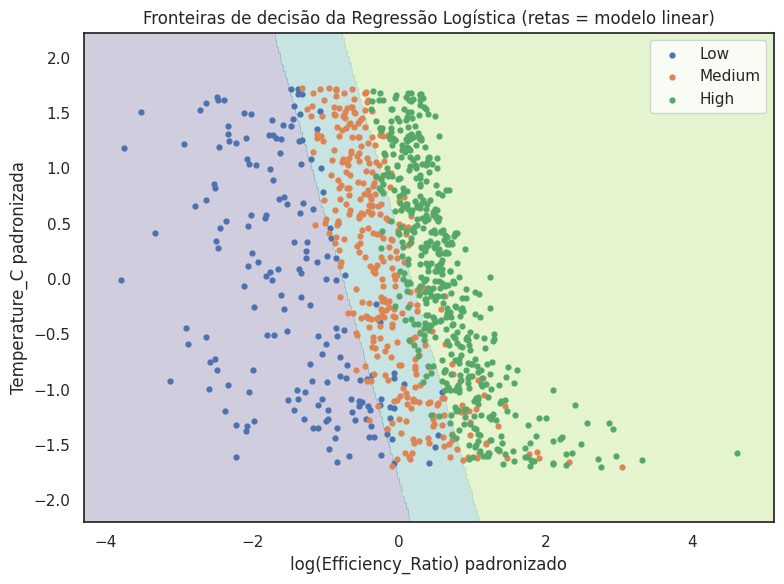

In [8]:
# Visualização da fronteira linear em 2 features (só ilustração)
X2 = StandardScaler().fit_transform(df[['Log_Efficiency_Ratio', 'Temperature_C']])
modelo_2d = LogisticRegression(max_iter=1000).fit(X2, y)

xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - .5, X2[:, 0].max() + .5, 400),
                     np.linspace(X2[:, 1].min() - .5, X2[:, 1].max() + .5, 400))
zz = modelo_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, zz, alpha=0.25, cmap='viridis', levels=[-0.5, 0.5, 1.5, 2.5])
for k, nome in enumerate(NOMES_CLASSES):
    plt.scatter(X2[y == k, 0], X2[y == k, 1], s=12, label=nome)
plt.xlabel('log(Efficiency_Ratio) padronizado')
plt.ylabel('Temperature_C padronizada')
plt.title('Fronteiras de decisão da Regressão Logística (retas = modelo linear)')
plt.legend()
plt.tight_layout()
plt.show()

### c) e d) Classificação nos dois cenários: 40% e 15% dos dados para teste

Usamos `stratify=y` para manter a proporção das classes no treino e no teste, e a mesma
semente nos dois cenários.

In [9]:
def treinar_e_avaliar(test_size):
    X_treino, X_teste, y_treino, y_teste = train_test_split(
        X, y, test_size=test_size, random_state=SEED, stratify=y)

    modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    modelo.fit(X_treino, y_treino)
    y_pred = modelo.predict(X_teste)

    return {
        'nome': f'Teste {int(test_size * 100)}%',
        'n_treino': len(X_treino), 'n_teste': len(X_teste),
        'y_teste': y_teste, 'y_pred': y_pred,
        'acuracia_treino': accuracy_score(y_treino, modelo.predict(X_treino)),
        'modelo': modelo,
    }


cenarios = [treinar_e_avaliar(0.40), treinar_e_avaliar(0.15)]
for c in cenarios:
    print(f"{c['nome']}: {c['n_treino']} amostras de treino | {c['n_teste']} amostras de teste")

Teste 40%: 600 amostras de treino | 400 amostras de teste
Teste 15%: 850 amostras de treino | 150 amostras de teste


## 03) Avaliação da performance
### b) Matriz de confusão de cada cenário


Matriz de confusão – Teste 40% (linhas = real, colunas = previsto):
             prev Low  prev Medium  prev High
real Low           59           12          0
real Medium         0          121         13
real High           0            6        189

Matriz de confusão – Teste 15% (linhas = real, colunas = previsto):
             prev Low  prev Medium  prev High
real Low           25            2          0
real Medium         0           42          8
real High           0            4         69


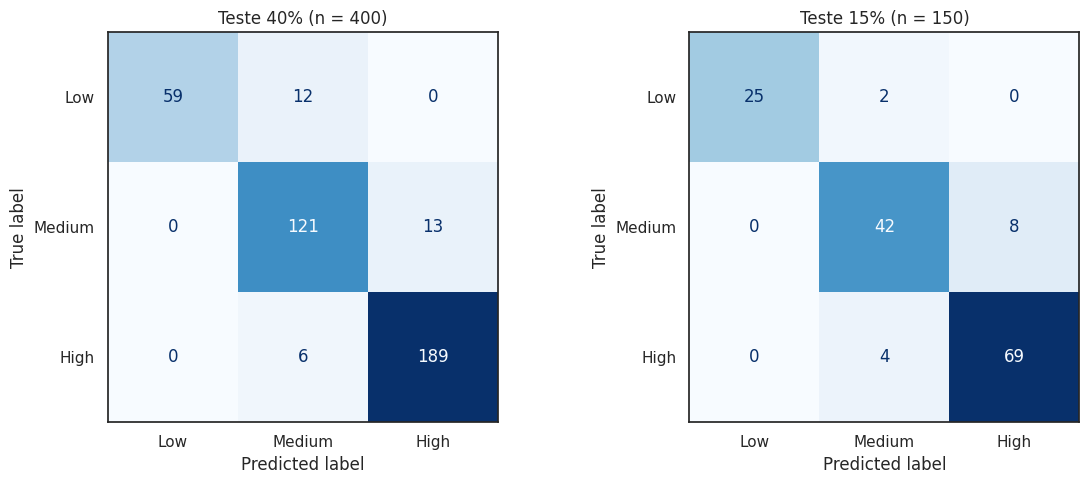

In [10]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
for c, eixo in zip(cenarios, eixos):
    cm = confusion_matrix(c['y_teste'], c['y_pred'], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=NOMES_CLASSES).plot(ax=eixo, cmap='Blues', colorbar=False)
    eixo.set_title(f"{c['nome']} (n = {c['n_teste']})")
    print(f"\nMatriz de confusão – {c['nome']} (linhas = real, colunas = previsto):")
    print(pd.DataFrame(cm, index=[f'real {n}' for n in NOMES_CLASSES],
                       columns=[f'prev {n}' for n in NOMES_CLASSES]))
plt.tight_layout()
plt.show()

### c) Acurácia geral, precisão e recall de cada cenário

In [11]:
linhas = []
for c in cenarios:
    yt, yp = c['y_teste'], c['y_pred']
    prec = precision_score(yt, yp, average=None, labels=[0, 1, 2], zero_division=0)
    rec = recall_score(yt, yp, average=None, labels=[0, 1, 2], zero_division=0)
    linha = {'Cenário': c['nome'],
             'Acurácia (teste)': accuracy_score(yt, yp),
             'Acurácia (treino)': c['acuracia_treino'],
             'Precisão (macro)': precision_score(yt, yp, average='macro', zero_division=0),
             'Recall (macro)': recall_score(yt, yp, average='macro', zero_division=0)}
    for k, nome in enumerate(NOMES_CLASSES):
        linha[f'Precisão {nome}'] = prec[k]
        linha[f'Recall {nome}'] = rec[k]
    linhas.append(linha)

resultados = pd.DataFrame(linhas).set_index('Cenário')
print(resultados.T)

for c in cenarios:
    print(f"\n===== Relatório de classificação – {c['nome']} =====")
    print(classification_report(c['y_teste'], c['y_pred'], target_names=NOMES_CLASSES, digits=3))

Cenário            Teste 40%  Teste 15%
Acurácia (teste)       0.922      0.907
Acurácia (treino)      0.925      0.926
Precisão (macro)       0.935      0.924
Recall (macro)         0.901      0.904
Precisão Low           1.000      1.000
Recall Low             0.831      0.926
Precisão Medium        0.871      0.875
Recall Medium          0.903      0.840
Precisão High          0.936      0.896
Recall High            0.969      0.945

===== Relatório de classificação – Teste 40% =====
              precision    recall  f1-score   support

         Low      1.000     0.831     0.908        71
      Medium      0.871     0.903     0.886       134
        High      0.936     0.969     0.952       195

    accuracy                          0.922       400
   macro avg      0.935     0.901     0.915       400
weighted avg      0.925     0.922     0.922       400


===== Relatório de classificação – Teste 15% =====
              precision    recall  f1-score   support

         Low      1.

In [12]:
# Confirmação do item 1d: poucas features x todas as features (mesmas divisões de 40% e 15%)
X_todas = pd.get_dummies(df.drop(columns=['Energy_Class', 'Energy_Class_num', 'Efficiency_Ratio']),
                         columns=CATEGORICAS, dtype=int)  # 18 colunas (com o log da eficiência)
conjuntos = {
    'Só log(Efficiency_Ratio) (1 feature)': df[['Log_Efficiency_Ratio']],
    'Escolhidas no item 1d (7 features)': X,
    f'Todas as colunas ({X_todas.shape[1]} features)': X_todas,
}
comparacao_features = {}
for nome, Xc in conjuntos.items():
    for test_size in [0.40, 0.15]:
        X_tr, X_te, y_tr, y_te = train_test_split(Xc, y, test_size=test_size,
                                                  random_state=SEED, stratify=y)
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
        comparacao_features.setdefault(nome, {})[f'Acurácia teste {int(test_size * 100)}%'] = \
            accuracy_score(y_te, m.predict(X_te))
print(pd.DataFrame(comparacao_features).T)

                                      Acurácia teste 40%  Acurácia teste 15%
Só log(Efficiency_Ratio) (1 feature)               0.745               0.660
Escolhidas no item 1d (7 features)                 0.922               0.907
Todas as colunas (18 features)                     0.910               0.900


In [13]:
# Referência (baseline): um "modelo" que sempre chuta a classe mais frequente (High)
baseline = y.value_counts(normalize=True).max()
print(f'Acurácia do baseline (sempre prever "High"): {baseline:.3f}')

Acurácia do baseline (sempre prever "High"): 0.486


           mean   std   min   max
Cenário                          
Teste 15% 0.914 0.019 0.867 0.960
Teste 40% 0.912 0.010 0.892 0.932


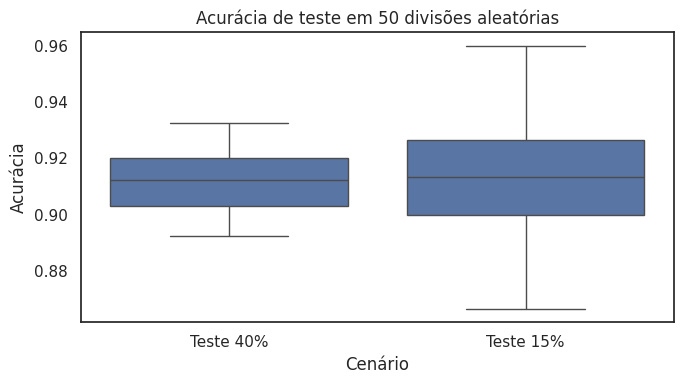

In [14]:
# Experimento extra para o item 3e: repetir cada cenário com 50 divisões aleatórias diferentes
# e medir quanto a acurácia de teste varia de uma divisão para outra.
variacao = []
for test_size in [0.40, 0.15]:
    for semente in range(50):
        X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size,
                                                  random_state=semente, stratify=y)
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
        variacao.append({'Cenário': f'Teste {int(test_size * 100)}%',
                         'Acurácia': accuracy_score(y_te, m.predict(X_te))})

variacao = pd.DataFrame(variacao)
print(variacao.groupby('Cenário')['Acurácia'].agg(['mean', 'std', 'min', 'max']))

plt.figure(figsize=(7, 4))
sns.boxplot(data=variacao, x='Cenário', y='Acurácia')
plt.title('Acurácia de teste em 50 divisões aleatórias')
plt.tight_layout()
plt.show()

### a) e d) A performance foi "boa"? Comentário dos resultados

**Depende de como avaliamos**, e por isso olhamos várias métricas:

* **Acurácia geral:** 92,2% (teste 40%) e 90,7% (teste 15%). Comparada ao baseline de
  48,6% (sempre chutar "High"), é um ganho grande. Mas a acurácia sozinha engana em dados
  desbalanceados como este (High 48,6%, Medium 33,6%, Low 17,8%): ela é dominada pela classe
  majoritária.
* **Precisão e recall por classe** mostram o que a acurácia esconde:
  - **Low:** precisão de 100% nos dois casos (quando o modelo diz "Low", acerta sempre), mas
    recall de 83,1% (40%) e 92,6% (15%): parte dos casos Low é classificada como Medium.
  - **Medium:** é a classe mais difícil (precisão ≈ 87%, recall entre 84% e 90%), porque fica
    "no meio" e é confundida com as duas vizinhas.
  - **High:** recall alto (94,5% a 96,9%), quase todos os casos High são encontrados.
* **Matriz de confusão:** **nenhum erro "pula" de Low para High ou vice-versa.** Todos os erros
  acontecem entre classes vizinhas (Low↔Medium e Medium↔High), o que faz sentido para um target
  ordinal e para um modelo linear: as fronteiras retas separam bem as faixas extremas e erram
  perto das bordas entre faixas.
* **Treino x teste:** acurácia de treino ≈ 92,5% e de teste ≈ 91–92%, quase iguais. Não há
  overfitting, o que é esperado de um modelo linear simples.

**Conclusão:** sim, a performance é boa, com macro-recall ≈ 90% e acerto equilibrado entre as
classes. Duas ressalvas: (1) a classe Medium é o ponto fraco; (2) o desempenho vem quase todo
de `Efficiency_Ratio`, que pode ter vazamento de informação do target (ver item 1d). Sem ela,
as variáveis climáticas sozinhas não sustentariam esse resultado.

### e) Comparação: test set de 40% x test set de 15%

**O que ocorreu:** na divisão fixa (semente 42), o teste de 40% teve acurácia um pouco maior
(92,2% x 90,7%). Mas essa diferença **não é real**: repetindo com 50 divisões aleatórias, a
**média é a mesma** (≈ 91% nos dois casos). O que muda é a **variação**: o desvio padrão é
≈ 1,0 ponto percentual com 40% e ≈ 1,9 p.p. com 15%. Com 15%, a acurácia oscilou entre
~87% e 96%, dependendo só de quais linhas caíram no teste.

Isso acontece porque, com 15%, o teste tem só 150 amostras (apenas 27 da classe Low). Cada erro
pesa 0,67 p.p. na acurácia e quase 4 p.p. no recall da Low. Com 40% são 400 amostras e cada
erro pesa só 0,25 p.p.

| | Test set maior (40%) | Test set menor (15%) |
|---|---|---|
| **Vantagem** | Avaliação mais **confiável e estável**: mais amostras de cada classe, inclusive a minoritária (71 Low), então as métricas variam menos | **Mais dados para treinar** (850 x 600), o que tende a gerar um modelo melhor, principalmente em modelos complexos ou bases pequenas |
| **Desvantagem** | **Menos dados para treinar**: o modelo aprende com 40% a menos de exemplos | Avaliação **instável e pouco confiável**: poucas amostras por classe, então o resultado depende muito da sorte na divisão |

Neste dataset, a regressão logística tem poucos parâmetros e já aprende bem com 600 amostras,
então treinar com 850 não trouxe ganho. Aqui, **o teste de 40% é a escolha mais segura**,
porque dá uma estimativa mais confiável sem perder desempenho. Na prática, uma boa solução para
esse dilema é a **validação cruzada (k-fold)**, que usa todos os dados para treino e teste em
rodadas alternadas.